In [1]:

%pip install -q qiskit qiskit-machine-learning scikit-learn pandas numpy matplotlib seaborn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.8 MB/s eta 0:00:00


In [2]:

import qiskit
from qiskit import QuantumCircuit

print("Qiskit version:", qiskit.__version__)

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)

print(qc.draw())


Qiskit version: 2.5.2
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘


In [3]:

from qiskit.circuit.library import zz_feature_map

feature_map = zz_feature_map(
    feature_dimension=4,
    reps=1,
    entanglement="linear"
)

print("Number of qubits:", feature_map.num_qubits)
print(feature_map.draw(output="text"))


Number of qubits: 4
   ┌───┐┌───────────┐                                               »
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■───────»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐     »
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■──»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                          └───┘»
3: ┤ H ├┤ P(2*x[3]) ├───────────────────────────────────────────────»
   └───┘└───────────┘                                               »
«                                                                             »
«0: ──────────────────────────────────────────────────────────────────────────»
«                                                                             »
«1: ──────────────────────────────────■───────────────────────────────────────»
«   ┌─────────────────────────

In [4]:

import pandas as pd
import numpy as np

# Download the NSL-KDD training dataset
train_url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"

# Download the NSL-KDD testing dataset
test_url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt"

columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files",
    "num_outbound_cmds", "is_host_login", "is_guest_login",
    "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty"
]

train_df = pd.read_csv(train_url, names=columns)
test_df = pd.read_csv(test_url, names=columns)

print("Dataset loaded successfully!")
print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

display(train_df.head())


Dataset loaded successfully!
Training data: (125973, 43)
Testing data: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [5]:

# Keep numeric network features for our first prototype
categorical_columns = ["protocol_type", "service", "flag"]

X_train = train_df.drop(
    columns=["label", "difficulty"] + categorical_columns
).copy()

X_test = test_df.drop(
    columns=["label", "difficulty"] + categorical_columns
).copy()

# Normal traffic = 0; attack traffic = 1
y_train = (train_df["label"] != "normal").astype(int)
y_test = (test_df["label"] != "normal").astype(int)

print("Data preparation completed!")
print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts().rename({0: "Normal", 1: "Attack"}))


Data preparation completed!

Training features: (125973, 38)
Testing features: (22544, 38)

Training labels:
label
Normal    67343
Attack    58630
Name: count, dtype: int64


In [6]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Scale the network features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the classical machine-learning model
classical_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

start_time = time.time()

classical_model.fit(X_train_scaled, y_train)

training_time = time.time() - start_time

# Predict normal traffic and attacks
classical_predictions = classical_model.predict(X_test_scaled)

print("Classical model trained successfully!")
print("Training time:", round(training_time, 2), "seconds")

print("\nModel performance:")
print(classification_report(
    y_test,
    classical_predictions,
    target_names=["Normal", "Attack"],
    zero_division=0
))


Classical model trained successfully!
Training time: 16.12 seconds

Model performance:
              precision    recall  f1-score   support

      Normal       0.66      0.97      0.79      9711
      Attack       0.97      0.62      0.75     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.80      0.77     22544
weighted avg       0.83      0.77      0.77     22544



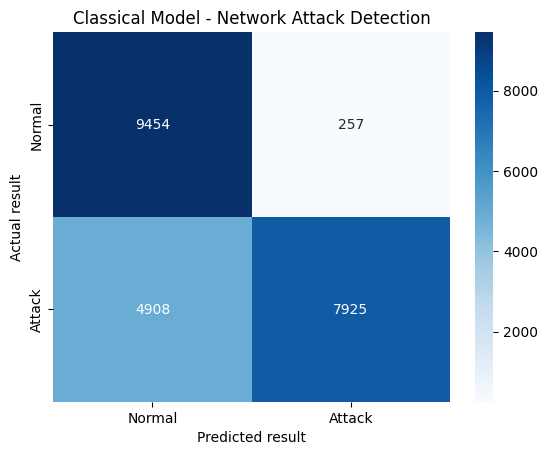

In [7]:

cm = confusion_matrix(y_test, classical_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)

plt.xlabel("Predicted result")
plt.ylabel("Actual result")
plt.title("Classical Model - Network Attack Detection")
plt.show()


In [8]:

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Select the 4 most informative numeric features
selector = SelectKBest(score_func=f_classif, k=4)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

selected_features = X_train.columns[selector.get_support()].tolist()

print("Selected network features:", selected_features)

# Scale values into the range 0 to 1
minmax_scaler = MinMaxScaler()

X_train_scaled4 = minmax_scaler.fit_transform(X_train_selected)
X_test_scaled4 = minmax_scaler.transform(X_test_selected)

# Use small samples to make quantum calculations manageable
rng = np.random.default_rng(42)

train_idx = rng.choice(
    len(X_train_scaled4),
    size=min(200, len(X_train_scaled4)),
    replace=False
)

test_idx = rng.choice(
    len(X_test_scaled4),
    size=min(80, len(X_test_scaled4)),
    replace=False
)

X_train_quantum = np.pi * X_train_scaled4[train_idx]
X_test_quantum = np.pi * X_test_scaled4[test_idx]

y_train_quantum = y_train.iloc[train_idx].to_numpy()
y_test_quantum = y_test.iloc[test_idx].to_numpy()

print("Quantum training data:", X_train_quantum.shape)
print("Quantum testing data:", X_test_quantum.shape)
print("Data prepared for the quantum model!")


Selected network features: ['logged_in', 'same_srv_rate', 'dst_host_srv_count', 'dst_host_same_srv_rate']
Quantum training data: (200, 4)
Quantum testing data: (80, 4)
Data prepared for the quantum model!


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [16] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [9]:

from qiskit.circuit.library import zz_feature_map

# Four input features are encoded into four qubits
feature_map = zz_feature_map(
    feature_dimension=4,
    reps=1,
    entanglement="linear"
)

print("Quantum feature map created!")
print("Number of qubits:", feature_map.num_qubits)
print("\nQuantum circuit:")
print(feature_map.draw(output="text"))


Quantum feature map created!
Number of qubits: 4

Quantum circuit:
   ┌───┐┌───────────┐                                               »
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■───────»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐     »
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■──»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                          └───┘»
3: ┤ H ├┤ P(2*x[3]) ├───────────────────────────────────────────────»
   └───┘└───────────┘                                               »
«                                                                             »
«0: ──────────────────────────────────────────────────────────────────────────»
«                                                                             »
«1: ──────────────────────────────────■────────────────────────

In [10]:

from qiskit_machine_learning.kernels import FidelityQuantumKernel
from sklearn.svm import SVC
from sklearn.metrics import classification_report
import time

# Build the quantum kernel
quantum_kernel = FidelityQuantumKernel(
    feature_map=feature_map
)

# Use the quantum kernel inside a classical SVM
quantum_model = SVC(
    kernel=quantum_kernel.evaluate,
    class_weight="balanced"
)

start_time = time.time()

quantum_model.fit(
    X_train_quantum,
    y_train_quantum
)

print("Quantum model training completed!")
print("Training time:", round(time.time() - start_time, 2), "seconds")

# Predict test traffic
quantum_predictions = quantum_model.predict(X_test_quantum)

print("\nQuantum model results:")
print(classification_report(
    y_test_quantum,
    quantum_predictions,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))


Quantum model training completed!
Training time: 130.47 seconds

Quantum model results:
              precision    recall  f1-score   support

      Normal       0.64      0.94      0.76        34
      Attack       0.93      0.61      0.74        46

    accuracy                           0.75        80
   macro avg       0.79      0.77      0.75        80
weighted avg       0.81      0.75      0.75        80



Q-SENTINEL: Classical vs Quantum Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score
0,Classical Random Forest,0.788,1.000,0.630,0.773
1,Quantum SVM,0.750,0.933,0.609,0.737


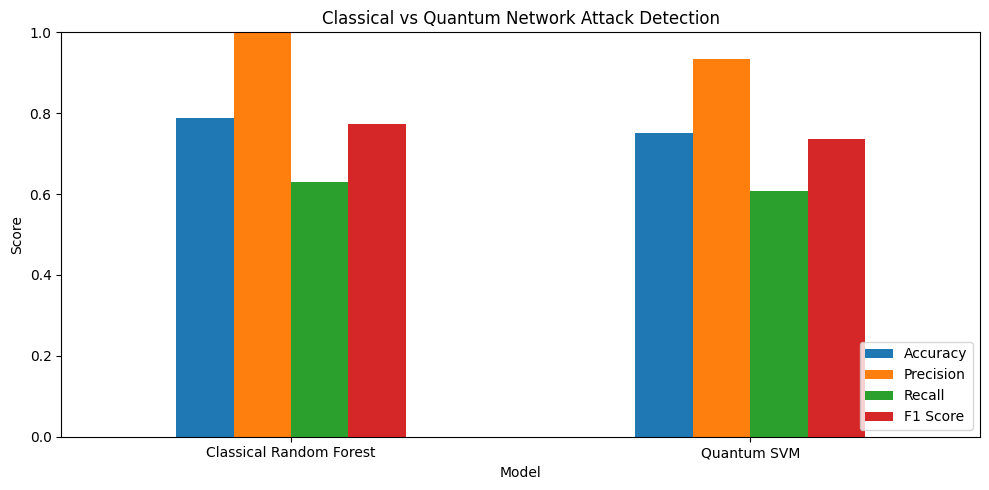

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

# Classical model predictions on the same test samples as the quantum model
classical_subset_predictions = classical_model.predict(X_test_scaled[test_idx])

# Compare both models
results = pd.DataFrame([
    {
        "Model": "Classical Random Forest",
        "Accuracy": accuracy_score(y_test_quantum, classical_subset_predictions),
        "Precision": precision_score(y_test_quantum, classical_subset_predictions, zero_division=0),
        "Recall": recall_score(y_test_quantum, classical_subset_predictions, zero_division=0),
        "F1 Score": f1_score(y_test_quantum, classical_subset_predictions, zero_division=0)
    },
    {
        "Model": "Quantum SVM",
        "Accuracy": accuracy_score(y_test_quantum, quantum_predictions),
        "Precision": precision_score(y_test_quantum, quantum_predictions, zero_division=0),
        "Recall": recall_score(y_test_quantum, quantum_predictions, zero_division=0),
        "F1 Score": f1_score(y_test_quantum, quantum_predictions, zero_division=0)
    }
])

print("Q-SENTINEL: Classical vs Quantum Model Comparison")
display(results.round(3))

# Plot the comparison
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)

plt.title("Classical vs Quantum Network Attack Detection")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [12]:
# Step 11: Inspect the attack types in the dataset

print("Attack types available in the training dataset:")
print(train_df["label"].value_counts().head(20))

print("\nAttack types available in the testing dataset:")
print(test_df["label"].value_counts().head(20))

Attack types available in the training dataset:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
Name: count, dtype: int64

Attack types available in the testing dataset:
label
normal             9711
neptune            4657
guess_passwd       1231
mscan               996
warezmaster         944
apache2             737
satan               735
processtable        685
smurf               665
back                359
snmpguess           331
saint               319
mailbomb            293
snmpgetattack       178
portsweep           157
ipswee

In [13]:
# Step 12: Prepare data for unseen attack detection

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np

# Attack family intentionally excluded from training
unseen_attack = "ipsweep"

# Use the original numeric network features
categorical_columns = ["protocol_type", "service", "flag"]
feature_columns = [
    col for col in train_df.columns
    if col not in ["label", "difficulty"] + categorical_columns
]

# Training data: normal traffic and all attacks except ipsweep
known_train = train_df[train_df["label"] != unseen_attack].copy()

X_known_train = known_train[feature_columns]
y_known_train = (known_train["label"] != "normal").astype(int)

# Testing data: normal traffic plus ipsweep examples
unseen_test = test_df[
    (test_df["label"] == "normal") |
    (test_df["label"] == unseen_attack)
].copy()

X_unseen_test = unseen_test[feature_columns]
y_unseen_test = (unseen_test["label"] != "normal").astype(int)

# Scale using training data only
unseen_scaler = StandardScaler()
X_known_train_scaled = unseen_scaler.fit_transform(X_known_train)
X_unseen_test_scaled = unseen_scaler.transform(X_unseen_test)

print("Excluded attack family:", unseen_attack)
print("Training samples:", len(X_known_train))
print("Testing samples:", len(X_unseen_test))

print("\nTraining labels:")
print(y_known_train.value_counts().rename({0: "Normal", 1: "Known attacks"}))

print("\nTesting labels:")
print(unseen_test["label"].value_counts())

print("\nData preparation completed!")

Excluded attack family: ipsweep
Training samples: 122374
Testing samples: 9852

Training labels:
label
Normal           67343
Known attacks    55031
Name: count, dtype: int64

Testing labels:
label
normal     9711
ipsweep     141
Name: count, dtype: int64

Data preparation completed!


In [14]:
# Step 13: Train the model without ipsweep attacks

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Create and train the model
unseen_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

start_time = time.time()

unseen_model.fit(
    X_known_train_scaled,
    y_known_train
)

training_time = time.time() - start_time

print("Unseen-attack experiment model trained!")
print("Training time:", round(training_time, 2), "seconds")

# Test on normal traffic and the excluded ipsweep family
unseen_predictions = unseen_model.predict(X_unseen_test_scaled)

print("\nUnseen-Attack Detection Results:")
print(
    classification_report(
        y_unseen_test,
        unseen_predictions,
        labels=[0, 1],
        target_names=["Normal", "Attack (ipsweep)"],
        zero_division=0
    )
)

Unseen-attack experiment model trained!
Training time: 24.63 seconds

Unseen-Attack Detection Results:
                  precision    recall  f1-score   support

          Normal       0.99      0.97      0.98      9711
Attack (ipsweep)       0.15      0.33      0.21       141

        accuracy                           0.96      9852
       macro avg       0.57      0.65      0.60      9852
    weighted avg       0.98      0.96      0.97      9852



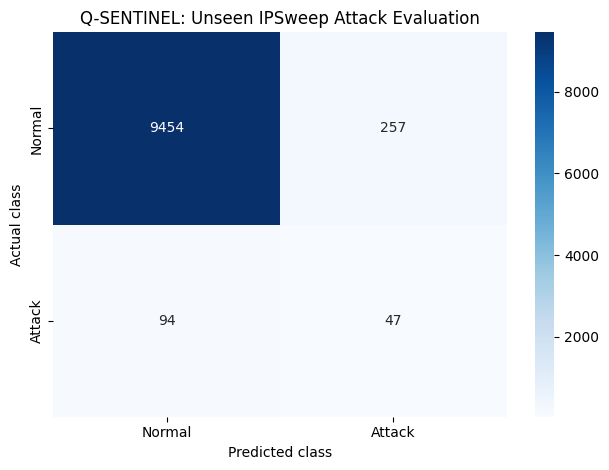

In [15]:
cm = confusion_matrix(
    y_unseen_test,
    unseen_predictions,
    labels=[0, 1]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Q-SENTINEL: Unseen IPSweep Attack Evaluation")
plt.tight_layout()
plt.show()

Q-SENTINEL | EXPERIMENT RESULTS


,Experiment,Accuracy,Precision,Recall,F1 Score
0,Classical Random Forest,0.788,1.000,0.630,0.773
1,Quantum SVM,0.750,0.933,0.609,0.737
2,Unseen IPSweep Test,0.964,0.155,0.333,0.211


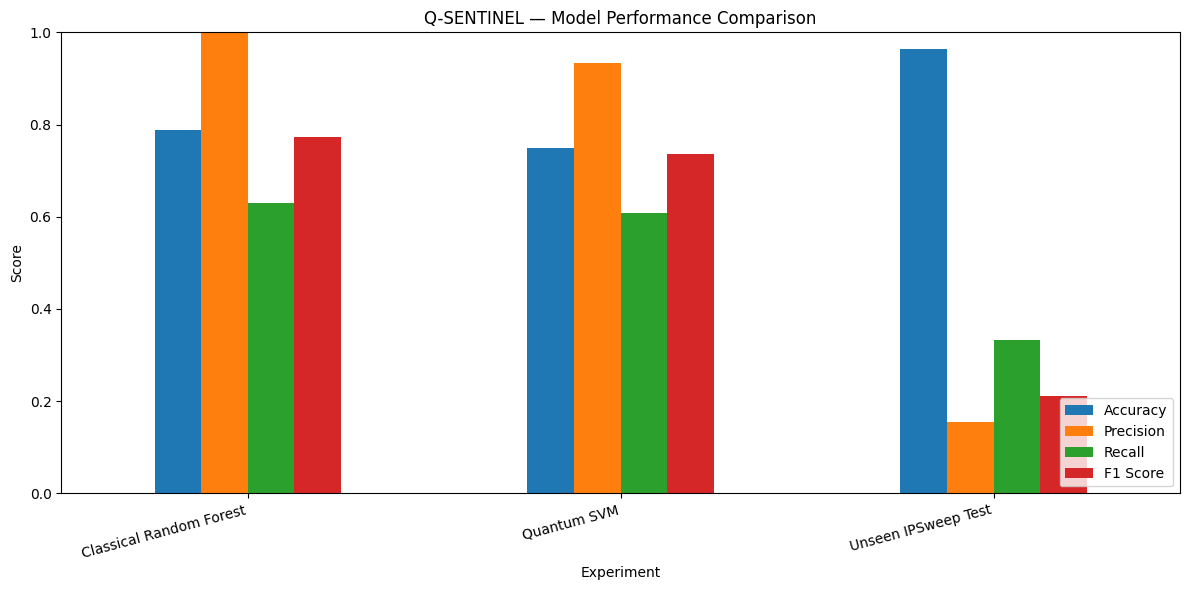

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Collect actual experiment results
dashboard_results = pd.DataFrame([
    {
        "Experiment": "Classical Random Forest",
        "Accuracy": accuracy_score(
            y_test_quantum, classical_subset_predictions
        ),
        "Precision": precision_score(
            y_test_quantum, classical_subset_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_quantum, classical_subset_predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_quantum, classical_subset_predictions, zero_division=0
        )
    },
    {
        "Experiment": "Quantum SVM",
        "Accuracy": accuracy_score(y_test_quantum, quantum_predictions),
        "Precision": precision_score(
            y_test_quantum, quantum_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_quantum, quantum_predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_quantum, quantum_predictions, zero_division=0
        )
    },
    {
        "Experiment": "Unseen IPSweep Test",
        "Accuracy": accuracy_score(y_unseen_test, unseen_predictions),
        "Precision": precision_score(
            y_unseen_test, unseen_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_unseen_test, unseen_predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_unseen_test, unseen_predictions, zero_division=0
        )
    }
])

print("Q-SENTINEL | EXPERIMENT RESULTS")
display(dashboard_results.round(3))

# Plot the measured scores
dashboard_results.set_index("Experiment")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(12, 6), ylim=(0, 1))

plt.title("Q-SENTINEL — Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Experiment")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [17]:
# Step 15: Save experiment results

from google.colab import files
import pandas as pd

# Save the dashboard results
dashboard_results.to_csv(
    "Q_SENTINEL_Experiment_Results.csv",
    index=False
)

print("Results saved successfully!")
display(dashboard_results.round(3))

# Download the CSV file
files.download("Q_SENTINEL_Experiment_Results.csv")

Results saved successfully!


,Experiment,Accuracy,Precision,Recall,F1 Score
0,Classical Random Forest,0.788,1.000,0.630,0.773
1,Quantum SVM,0.750,0.933,0.609,0.737
2,Unseen IPSweep Test,0.964,0.155,0.333,0.211


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# Save actual and predicted labels for the unseen-attack experiment

unseen_results = pd.DataFrame({
    "Actual_Label": unseen_test["label"].to_numpy(),
    "Actual_Class": y_unseen_test.to_numpy(),
    "Predicted_Class": unseen_predictions
})

unseen_results["Prediction"] = unseen_results["Predicted_Class"].map({
    0: "Normal",
    1: "Attack"
})

unseen_results.to_csv(
    "Q_SENTINEL_Unseen_Attack_Predictions.csv",
    index=False
)

print("Unseen-attack predictions saved!")
files.download("Q_SENTINEL_Unseen_Attack_Predictions.csv")

Unseen-attack predictions saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
from google.colab import files

dashboard_results.to_csv(
    "Q_SENTINEL_Experiment_Results.csv",
    index=False
)

print("Results saved successfully!")

files.download("Q_SENTINEL_Experiment_Results.csv")

Results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from google.colab import files
import pandas as pd

unseen_results = pd.DataFrame({
    "Actual_Label": unseen_test["label"].to_numpy(),
    "Actual_Class": y_unseen_test.to_numpy(),
    "Predicted_Class": unseen_predictions
})

unseen_results["Prediction"] = unseen_results["Predicted_Class"].map({
    0: "Normal",
    1: "Attack"
})

unseen_results.to_csv(
    "Q_SENTINEL_Unseen_Attack_Predictions.csv",
    index=False
)

print("Unseen-attack results saved!")

files.download("Q_SENTINEL_Unseen_Attack_Predictions.csv")

Unseen-attack results saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>